# 成员 C：气象特征分析与提取

本 notebook 负责气象数据的描述性分析、候选特征构造及特征说明表。内容包括 Pearson 相关性、温度分箱曲线、风速分布、月份—小时分组控制，以及可交给 B 的气象特征表。

所有代码均可在 Jupyter 中从上到下运行。负荷按项目约定暂用 **kW**；CSV 本身没有注明完整单位，风速、GDF、DF 保留原始单位。图表与表格直接内嵌在本文件中。

沿用原文件的 **1—7 月探索范围**。原始数据保留全年范围；气象特征按完整时间序列生成，再用分析期检查其统计分布。候选特征的含义与相关性不等于已确认的独立影响。

## 1. 环境与分析参数

### 代码详解 1：准备依赖、字段和路径

- `Path`用于定位CSV；`hashlib`记录数据文件摘要；`numpy`和`pandas`用于数值运算、读表、分组与滚动统计。
- `matplotlib`负责画图；`font_manager`查找中文字体；`gaussian_kde`绘制平滑风速密度；`display`与`Markdown`显示表格和结论。
- `%matplotlib inline`让图显示在Jupyter中；`rcParams`统一中文字体、字号与负号。
- `WEATHER`定义五个原始气象字段，`ZONES`定义三个分区。`EXPLORE_END`是分析期结束边界，不包含当天。
- 从当前目录及父目录寻找指定CSV，得到项目根路径`ROOT`，找不到就报错。

依赖缺失时，可在当前内核运行注释中的安装命令，然后重启内核。

In [1]:
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from scipy.stats import gaussian_kde
from IPython.display import display, Markdown

%matplotlib inline
# 缺少依赖时，在当前内核运行：
# %pip install numpy pandas matplotlib scipy
fonts = {f.name for f in font_manager.fontManager.ttflist}
font = next((f for f in ['Microsoft YaHei', 'SimHei', 'Noto Sans CJK SC', 'PingFang SC'] if f in fonts), 'DejaVu Sans')
plt.rcParams.update({'font.sans-serif': [font], 'axes.unicode_minus': False,
                     'font.size': 11, 'figure.dpi': 130})
WEATHER = ['T', 'RH', 'WS', 'GDF', 'DF']
ZONES = ['Z1', 'Z2', 'Z3']
EXPLORE_END = pd.Timestamp('2017-08-01')
roots = [Path.cwd()] + list(Path.cwd().parents)
ROOT = next((r for r in roots if (r / 'data' / '题4_城市电力负荷.csv').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('请从 City_load 项目目录或其子目录启动 Jupyter。')
print('项目目录：', ROOT)
print('分析期结束边界（不包含）：', EXPLORE_END)

项目目录： C:\Users\Lenovo\Desktop\python\City_load
分析期结束边界（不包含）： 2017-08-01 00:00:00


## 2. 读取数据与质量检查

字段按名称映射，兼容原始列名中的双空格；检查时间连续性与数值完整性。保留原始记录，不因高负荷或风速双峰而自动删除。

### 代码详解 2：读取CSV、检查时间和构造总负荷

**输入：** 原始CSV。**输出：** 按时间排序的`df`、探索期子集`explore`和质量检查信息。

1. `ROOT/'data'/文件名`拼接路径；`with p.open(...)`打开文件并在读完后关闭。`utf-8-sig`兼容UTF-8文件可能带的BOM。
2. `' '.join(c.split())`把列名两端空白和连续空格规整为一个空格；例如分区2列原来的双空格不会再导致找不到列。
3. `rename`是原列名到短名的字典；`issubset`确认所需字段存在。`raw[list(rename)]`按字典键选列，`.rename(columns=rename)`改名，`.copy()`创建独立副本。
4. `pd.to_datetime(...,format=...)`明确按“月/日/年 时:分”解析；`pd.to_numeric`将气象与负荷转为数值。`errors='raise'`遇到无法解析的内容就报错，避免悄悄丢失记录。
5. `set_index('DateTime').sort_index()`将时间作为行索引并升序排列，为后面的滚动特征、按时间筛选和分组提供依据。
6. 各条`assert`依次检查：时间不能缺失或重复；数值必须有限；时间索引应与完整十分钟网格一致；风速不能为负。检查通过不代表所有业务异常都已排除。
7. `df[ZONES].sum(axis=1)`对每一行的三个分区相加，得到`Z_total`。`axis=1`是横向沿列求和，结果仍是该时刻的kW负荷，不是电量。
8. `df.index<EXPLORE_END`筛出8月1日之前的记录，再复制为`explore`。后面描述性图只用该子集。
9. `normalize().nunique()`统计不同日期数；`isna()`和`duplicated()`统计缺失与重复；`head()`显示前5行便于人工核对。

In [2]:
p = ROOT/'data'/'题4_城市电力负荷.csv'
with p.open(encoding='utf-8-sig') as f: raw = pd.read_csv(f)
raw.columns = [' '.join(c.split()) for c in raw.columns]
rename = {'DateTime':'DateTime','Temperature':'T','Humidity':'RH','Wind Speed':'WS',
          'general diffuse flows':'GDF','diffuse flows':'DF','Zone 1 Power Consumption':'Z1',
          'Zone 2 Power Consumption':'Z2','Zone 3 Power Consumption':'Z3'}
assert set(rename).issubset(raw.columns), 'CSV字段不符合预期'
df = raw[list(rename)].rename(columns=rename).copy()
df['DateTime'] = pd.to_datetime(df['DateTime'], format='%m/%d/%Y %H:%M', errors='raise')
for c in WEATHER+ZONES: df[c] = pd.to_numeric(df[c], errors='raise')
df = df.set_index('DateTime').sort_index()
assert not df.index.hasnans and not df.index.duplicated().any(), '时间缺失或重复'
assert np.isfinite(df.values).all(), '存在数值缺失或无穷值'
assert df.index.equals(pd.date_range(df.index.min(),df.index.max(),freq='10min')), '时间网格不完整'
assert (df.WS>=0).all(), '负风速需核实'
df['Z_total'] = df[ZONES].sum(axis=1)
explore = df[df.index<EXPLORE_END].copy()
print('记录数：',len(df),'；天数：',df.index.normalize().nunique())
print('时间范围：',df.index.min(),'至',df.index.max())
print('缺失数：',int(df.isna().sum().sum()),'；重复时间数：',int(df.index.duplicated().sum()))
print('CSV SHA256：',hashlib.sha256(p.read_bytes()).hexdigest())
display(df.head())

记录数： 52416 ；天数： 364
时间范围： 2017-01-01 00:00:00 至 2017-12-30 23:50:00
缺失数： 0 ；重复时间数： 0
CSV SHA256： ca8b2f30cf07dd872cb7f2aa45dac110ee38dbe5fc5910a6ff4bcc530dae3a40


,T,RH,WS,GDF,DF,Z1,Z2,Z3,Z_total
DateTime,,,,,,,,,
2017-01-01 00:00:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386,70425.53544
2017-01-01 00:10:00,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434,69320.84387
2017-01-01 00:20:00,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373,67803.22193
2017-01-01 00:30:00,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711,65489.23209
2017-01-01 00:40:00,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964,63650.44627


## 3. Pearson相关性：描述气象与负荷的线性关联

使用1—7月的五个气象指标、三个分区及总负荷。相关性用于提出候选线索，不直接作为删列依据，也不代表因果关系。

### 代码详解 3：绘制Pearson相关性热力图

**输入：** 探索期的气象和负荷数值列。**输出：** 完整相关矩阵图、气象与负荷的系数表。

1. `heatmap(table,title,size)`定义可重复调用的画图函数。`table`是行列均有名称的DataFrame，`size`决定图尺寸。
2. `imshow`把矩阵值映射成颜色。`RdBu_r`使用红蓝色带；`vmin=-1,vmax=1`固定范围，方便不同热力图比较；`aspect='auto'`让图适应画布。
3. `set_xticks`/`set_yticks`确定格子位置，`set_*ticklabels`把变量名显示出来；横轴旋转35度以减少重叠。
4. 两层`for`遍历所有格子；`table.iloc[i,j]`按位置读取系数，`ax.text`在格子中心写两位小数。绝对相关系数大于0.6时改用白字，仅为了可读性，不是统计显著性阈值。
5. `colorbar`是颜色与系数的对照尺；`tight_layout`调整边距；`show`输出图片。
6. `.corr()`默认计算Pearson线性相关系数。`weather_corr=corr.loc[...]`只取气象行、负荷列，得到适合报告引用的小表。
7. `.round(3)`只是显示到三位小数，不会把原来的`corr`值改成低精度。

**解释：** 正值表示同向线性关联，负值表示反向线性关联；接近0仅表示线性关联弱。

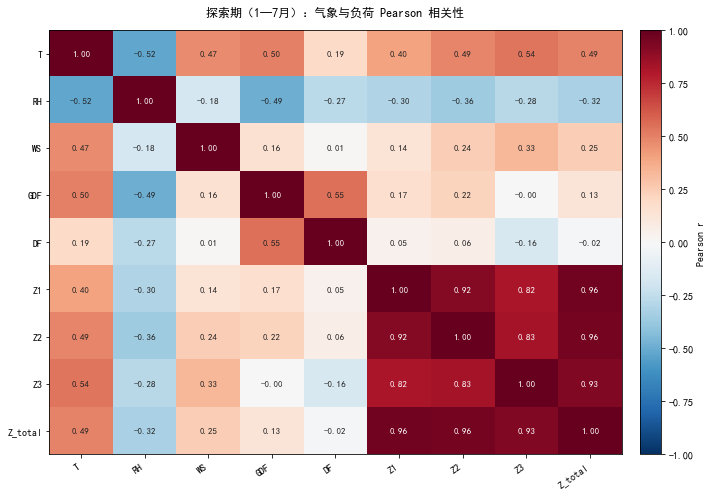

,Z1,Z2,Z3,Z_total
T,0.399,0.486,0.539,0.494
RH,-0.300,-0.359,-0.278,-0.324
WS,0.138,0.244,0.334,0.245
GDF,0.168,0.219,-0.001,0.130
DF,0.047,0.063,-0.158,-0.020


In [3]:
def heatmap(table,title,size=(10,7)):
    fig,ax=plt.subplots(figsize=size)
    im=ax.imshow(table.values,cmap='RdBu_r',vmin=-1,vmax=1,aspect='auto')
    ax.set_xticks(np.arange(table.shape[1])); ax.set_yticks(np.arange(table.shape[0]))
    ax.set_xticklabels(table.columns,rotation=35,ha='right'); ax.set_yticklabels(table.index)
    for i in range(table.shape[0]):
        for j in range(table.shape[1]):
            v=table.iloc[i,j]
            ax.text(j,i,'{:.2f}'.format(v),ha='center',va='center',fontsize=9,
                    color='white' if abs(v)>.6 else '#222222')
    ax.set_title(title,pad=14)
    fig.colorbar(im,ax=ax,fraction=.04,pad=.03).set_label('Pearson r')
    fig.tight_layout(); plt.show()
corr=explore[WEATHER+ZONES+['Z_total']].corr()
weather_corr=corr.loc[WEATHER,ZONES+['Z_total']]
heatmap(corr,'探索期（1—7月）：气象与负荷 Pearson 相关性')
display(weather_corr.round(3))

## 4. 温度分箱：观察不同温度水平下的平均负荷

每箱默认 **2°C**，左闭右开；少于100条观测的箱不连线，统计表仍保留。标题、边界和柱宽同步使用`TEMP_BIN_WIDTH`。

### 代码详解 4：温度分箱曲线——逐步说明

**输入：** `explore`中的温度与三个分区、总负荷。**输出：** 上方平均负荷曲线、下方样本量柱状图及`temp_summary`。

1. `TEMP_BIN_WIDTH=2.0`表示每箱长度为**2°C**；`MIN_TEMP_SAMPLES=100`规定至少100条观测才在曲线中显示。标题从箱宽参数自动生成。
2. `min()`取探索期最低温。`np.floor(最低温/箱宽)*箱宽`将下边界向下对齐到箱宽整数倍。例如最低温3.25°C、箱宽2°C，得到下边界2°C。
3. 上边界使用`(floor(最高温/箱宽)+1)*箱宽`，保证严格高于最高温。例如最高温40.01°C时上边界是42°C；最高温恰好40°C时也用42°C，以免左闭右开区间漏掉40°C。
4. `np.arange(low,high+箱宽*0.5,箱宽)`产生2、4、6……这样的边界。`arange`的终点通常不包含在内，末端多加半个箱宽是为了把`high`这个边界纳入。旧写法`high+1`是在箱宽为2时的对应写法。
5. `temp=explore.copy()`复制数据，防止添加辅助列影响原来的探索表。
6. `pd.cut(...,right=False)`给每条记录分配温度区间，使用**左闭右开**规则：20°C属于`[20,22)`，22°C属于`[22,24)`。
7. `normalize()`将同一天的时间都变成当天00:00。这里只用于统计不同日期，没有把负荷按天平均。
8. `groupby('T_bin',observed=False)`按温度箱分组，保留边界定义出来的空箱，避免画图时直接跨过没有数据的温度段。
9. `g[ZONES+['Z_total']].mean()`分别计算每箱内三个分区和总负荷的算术平均；`g.size()`是每箱的十分钟观测数；`g['date'].nunique()`是每箱涉及的不同日期数。**它是每箱内所有观测的均值，不是先算日均再对日期平均。**
10. `interval.mid`取每个区间中点：`[20,22)`的横坐标为21°C。中点只是画图位置，不表示该箱内实测平均温度一定是21°C。
11. `subplots(2,1)`生成上下两幅图；`sharex=True`共用横轴；`height_ratios=[3,1]`使上图高度约为下图3倍。
12. `zip`将三个分区与三种颜色对应。`.where(temp_n>=100)`把不足100条观测的箱均值临时替换为NaN，使曲线断开；原始统计表和原始数据都保留。`.values`取出数组交给Matplotlib。
13. `plot`中的`marker='o'`画圆点，`lw=2`设置线宽，`label`用于图例。虽然统计表计算了总负荷，当前上图仅画三个分区，避免总负荷量级把分区曲线压低。
14. `set_title`标注“每箱2°C”；`legend(ncol=3)`把三个图例排成一行；`grid(alpha=0.2)`显示较淡网格。
15. 下方`bar`显示各箱观测数，柱宽为箱宽的80%，留出间隔。样本较少的高温/低温端点需要谨慎阅读。
16. `temp_summary`保留**所有箱**的均值并增加观测数、覆盖日期数；`.round(2)`仅调整展示精度。表中的稀疏箱仍可看到，但不应因曲线断点而误以为被删除。

**例子：** 某箱有120条十分钟记录，分区1负荷均值30000kW，则在该箱中点画出30000kW的点；若只有80条，统计表仍显示均值，但曲线不画这个点。120条记录可能来自多个日期，不能直接当作120个独立样本。

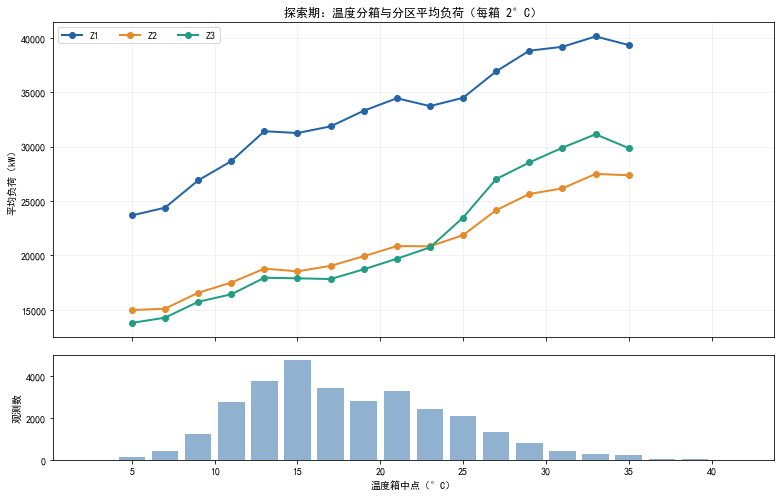

,Z1,Z2,Z3,Z_total,观测数,覆盖日期数
T_bin,,,,,,
"[2.0, 4.0)",24210.17,15028.18,13718.12,52956.47,22,1
"[4.0, 6.0)",23663.72,14962.07,13783.12,52408.92,157,6
"[6.0, 8.0)",24376.56,15091.36,14262.71,53730.62,419,16
"[8.0, 10.0)",26883.45,16554.75,15720.46,59158.66,1247,48
"[10.0, 12.0)",28653.85,17492.04,16410.55,62556.43,2794,76
"[12.0, 14.0)",31408.56,18772.49,17935.89,68116.94,3766,106
"[14.0, 16.0)",31241.03,18521.04,17880.52,67642.60,4784,121
"[16.0, 18.0)",31852.82,19030.20,17817.26,68700.29,3443,113
"[18.0, 20.0)",33290.31,19912.76,18707.59,71910.66,2809,106


In [4]:
# 每个温度箱覆盖 2°C；修改此参数，边界与标题会同步更新。
TEMP_BIN_WIDTH = 2.0
MIN_TEMP_SAMPLES = 100

# 下边界向下对齐到箱宽的整数倍；上边界必须严格大于最高温。
low = np.floor(explore['T'].min() / TEMP_BIN_WIDTH) * TEMP_BIN_WIDTH
high = (np.floor(explore['T'].max() / TEMP_BIN_WIDTH) + 1) * TEMP_BIN_WIDTH
edges = np.arange(low, high + TEMP_BIN_WIDTH * 0.5, TEMP_BIN_WIDTH)

temp = explore.copy()
temp['T_bin'] = pd.cut(temp['T'], edges, right=False)  # 左闭右开，如 [20, 22)
temp['date'] = temp.index.normalize()                 # 将时分秒归零，便于统计日期数
g = temp.groupby('T_bin', observed=False)

temp_means = g[ZONES + ['Z_total']].mean()
temp_n = g.size()
temp_days = g['date'].nunique()
centers = np.array([interval.mid for interval in temp_means.index])

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True,
                         gridspec_kw={'height_ratios': [3, 1]})
for zone, color in zip(ZONES, ['#2463A6', '#E58B2B', '#229C82']):
    plotted_means = temp_means[zone].where(temp_n >= MIN_TEMP_SAMPLES)
    axes[0].plot(centers, plotted_means.values, marker='o', lw=2, label=zone, color=color)
axes[0].set_title('探索期：温度分箱与分区平均负荷（每箱 {:g}°C）'.format(TEMP_BIN_WIDTH))
axes[0].set_ylabel('平均负荷（kW）')
axes[0].legend(ncol=3)
axes[0].grid(alpha=0.2)
axes[1].bar(centers, temp_n.values, width=TEMP_BIN_WIDTH * 0.8, color='#91B1D0')
axes[1].set_ylabel('观测数')
axes[1].set_xlabel('温度箱中点（°C）')
fig.tight_layout()
plt.show()

temp_summary = temp_means.copy()
temp_summary['观测数'] = temp_n
temp_summary['覆盖日期数'] = temp_days
display(temp_summary.round(2))

## 5. 风速分布：提取风速状态的候选表示

比较直方图、KDE及每月高风速比例。`WS>=4.8`来自数据已有的集中区间，只是候选阈值；风速双峰本身不足以证明记录错误或要求二值化。

### 代码详解 5：风速直方图、KDE及月度状态比例

**输入：** 探索期风速`WS`。**输出：** 风速分布图、每月高风速占比图和两个区间占比。

1. `.values`取得风速数组。`np.linspace(0,wind.max()*1.05,600)`创建600个均匀横坐标，最大值稍留余量。
2. `hist(...,bins=60,density=True)`将风速分成60箱，纵轴采用概率密度；不是观测条数，也不是每箱概率。直方图各柱“宽度×高度”的和约为1。
3. `gaussian_kde(wind)`拟合高斯核密度估计，后面的`(x)`在指定横坐标计算平滑密度。它帮助看分布形状，不会改变原始风速。
4. `(WS>=4.8)`产生布尔值；`.astype(float)`把True/False变为1/0；按月份求均值就得到每月满足条件的比例，乘100转成百分数。
5. 最后的两次比较分别统计`WS<0.2`和`WS>=4.8`的占比。这两个区间没有覆盖中间值，比例之和不要求100%。

**解释：** 双峰是分布形态；是否来自真实天气状态或记录问题，还需要数据来源与设备资料才能判定。

WS < 0.2：67.07%；WS >= 4.8：32.57%
双峰不等于数据错误；KDE在零边界附近有平滑偏差。


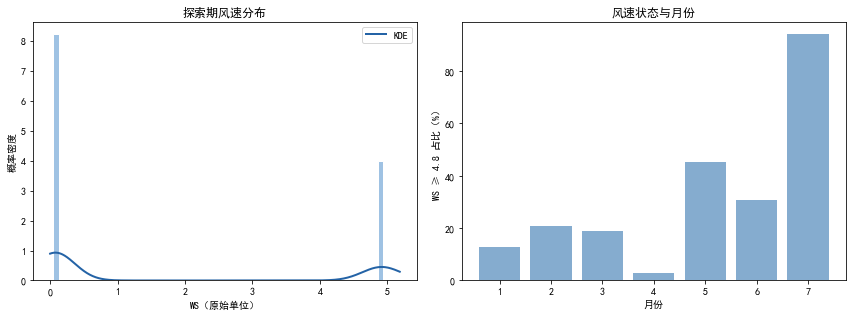

In [5]:
wind=explore['WS'].values
x=np.linspace(0,wind.max()*1.05,600)
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
axes[0].hist(wind,bins=60,density=True,color='#9FC2E3',edgecolor='white')
axes[0].plot(x,gaussian_kde(wind)(x),color='#2463A6',lw=2,label='KDE')
axes[0].set_xlabel('WS（原始单位）'); axes[0].set_ylabel('概率密度'); axes[0].set_title('探索期风速分布'); axes[0].legend()
high_share=(explore['WS']>=4.8).astype(float).groupby(explore.index.month).mean()
axes[1].bar(high_share.index,high_share.values*100,color='#85ACCF')
axes[1].set_xlabel('月份'); axes[1].set_ylabel('WS ≥ 4.8 占比（%）'); axes[1].set_title('风速状态与月份')
fig.tight_layout(); plt.show()
print('WS < 0.2：{:.2%}；WS >= 4.8：{:.2%}'.format((wind<.2).mean(),(wind>=4.8).mean()))
print('双峰不等于数据错误；KDE在零边界附近有平滑偏差。')

## 6. 月份—小时联合分组：区分时间结构与剩余关联

“月份×小时”表示联合分组，不做数值乘法。例如7月各天20:00—20:59属于同一组。将温度和负荷分别减去该组的自身均值后，再计算关联，观察原始关联中有多少与这类时间结构重合。

### 代码详解 6：减去"月份—小时联合分组"，检查剩余关联

**输入：** 探索期五个气象变量及总负荷。**输出：** 控制前后的相关系数对照表与柱状图。

1. `cols`确定参与分析的6列；分组键由`index.month`和`index.hour`共同组成。例如“7月、20时”的所有日期观测属于同一组。
2. `.groupby([...]).transform('mean')`计算每组每列均值，再将均值展开回原始行数，保证可以与每条原观测相减。
3. `within=原值−组均值`。例如某组温度均值28°C，一条观测30°C，剩余温度就是+2°C；负荷也减去自己的组均值。
4. 两次`.corr()['Z_total'].loc[WEATHER]`分别提取原始变量与总负荷、剩余变量与剩余总负荷的相关系数。
5. `DataFrame`将两组系数并排，`plot.bar`绘制对照柱；零线用于判断方向。

**解释：** 相关性减弱说明部分共同变化可以由这种时间分组解释，但控制不完整，不等于已经排除全部时间影响，更不是因果识别。

,原始同期r,扣除月份—小时联合分组均值后r
T,0.494,0.058
RH,-0.324,-0.078
WS,0.245,0.054
GDF,0.130,0.027
DF,-0.020,-0.052


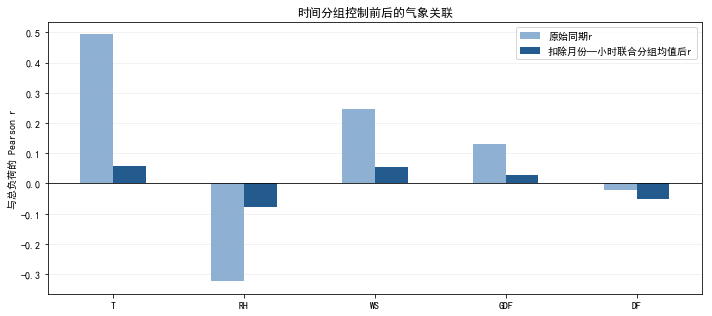

In [6]:
cols=WEATHER+['Z_total']
within=explore[cols]-explore[cols].groupby([explore.index.month.values,explore.index.hour.values]).transform('mean')
controlled_corr=pd.DataFrame({'原始同期r':explore[cols].corr()['Z_total'].loc[WEATHER],
                             '扣除月份—小时联合分组均值后r':within.corr()['Z_total'].loc[WEATHER]})
display(controlled_corr.round(3))
ax=controlled_corr.plot.bar(figsize=(10,4.5),color=['#8DB0D3','#245B8E'],rot=0)
ax.axhline(0,color='black',lw=.8); ax.set_ylabel('与总负荷的 Pearson r')
ax.set_title('时间分组控制前后的气象关联'); ax.grid(axis='y',alpha=.2)
plt.tight_layout(); plt.show()

## 7. 构造可交接的气象特征

### 代码详解 7：原始气象、近期水平、变化与组合特征

**输入：** 完整时间序列`df`的五个气象字段。**输出：** 以原时间为索引的`weather_features`，不含负荷列。

1. `df[WEATHER].copy()`保留5个原始气象变量；单独建立表，便于按时间与其他数据对齐。
2. `rolling(6,min_periods=6).mean()`计算当前及之前5条记录的均值。十分钟网格下，这是按6条记录定义的约1小时窗口；`rolling(144,...)`为约24小时窗口。它们是采样点算术平均，不是连续时间积分。
3. `min_periods`要求完整窗口，开头不足6条或144条时保留NaN，不拿后面的信息填补。
4. `T.shift(6)`取得1小时前温度；当前温度减去它得到`T_change_1h`，正数表示较1小时前升温，负数表示降温。
5. `T**2`给出温度平方；`T*RH`给出温湿度组合；它们只是候选表达，不能仅凭定义确认其重要性。
6. `(WS>=4.8).astype(int)`将原始风速集中区间表示为0/1，同时保留原始`WS`。不要将这个阈值解释为已经确认的物理风速等级。
7. 所有滚动窗口均向过去计算，包含当前观测；没有居中窗口、未来实测天气或向后填补。默认假定当前记录已到达且可用。
8. `assert`检查提取后时间索引与原表一致。`head(8)`用于看窗口开头的缺失，`tail(5)`查看完整特征示例。

得到的13列由5个原始变量与8个派生变量组成。派生列的单位在下一节说明；平方、乘积等列不与原始温度共用单位。

In [7]:
weather_features = df[WEATHER].copy()
# 近期温度水平：只使用当前及过去观测。
weather_features['T_mean_1h'] = df['T'].rolling(6, min_periods=6).mean()
weather_features['T_mean_24h'] = df['T'].rolling(144, min_periods=144).mean()
# 气温变化：相对于1小时前的变化量，而不是每小时导数。
weather_features['T_change_1h'] = df['T'] - df['T'].shift(6)
# 气象组合的候选表达。
weather_features['T_sq'] = df['T'] ** 2
weather_features['T_RH'] = df['T'] * df['RH']
weather_features['RH_mean_1h'] = df['RH'].rolling(6, min_periods=6).mean()
weather_features['WS_mean_1h'] = df['WS'].rolling(6, min_periods=6).mean()
weather_features['WS_high'] = (df['WS'] >= 4.8).astype(int)
assert weather_features.index.equals(df.index)
print('气象特征表尺寸：', weather_features.shape)
display(weather_features.head(8).round(3))
display(weather_features.tail(5).round(3))

气象特征表尺寸： (52416, 13)


,T,RH,WS,GDF,DF,T_mean_1h,T_mean_24h,T_change_1h,T_sq,T_RH,RH_mean_1h,WS_mean_1h,WS_high
DateTime,,,,,,,,,,,,,
2017-01-01 00:00:00,6.559,73.8,0.083,0.051,0.119,NaN,NaN,NaN,43.020,484.054,NaN,NaN,0
2017-01-01 00:10:00,6.414,74.5,0.083,0.070,0.085,NaN,NaN,NaN,41.139,477.843,NaN,NaN,0
2017-01-01 00:20:00,6.313,74.5,0.080,0.062,0.100,NaN,NaN,NaN,39.854,470.318,NaN,NaN,0
2017-01-01 00:30:00,6.121,75.0,0.083,0.091,0.096,NaN,NaN,NaN,37.467,459.075,NaN,NaN,0
2017-01-01 00:40:00,5.921,75.7,0.081,0.048,0.085,NaN,NaN,NaN,35.058,448.220,NaN,NaN,0
2017-01-01 00:50:00,5.853,76.9,0.081,0.059,0.108,6.197,NaN,NaN,34.258,450.096,75.067,0.082,0
2017-01-01 01:00:00,5.641,77.7,0.080,0.048,0.096,6.044,NaN,-0.918,31.821,438.306,75.717,0.081,0
2017-01-01 01:10:00,5.496,78.2,0.085,0.055,0.093,5.891,NaN,-0.918,30.206,429.787,76.333,0.082,0


,T,RH,WS,GDF,DF,T_mean_1h,T_mean_24h,T_change_1h,T_sq,T_RH,RH_mean_1h,WS_mean_1h,WS_high
DateTime,,,,,,,,,,,,,
2017-12-30 23:10:00,7.010,72.4,0.080,0.040,0.096,7.323,11.869,-0.630,49.140,507.524,71.367,0.081,0
2017-12-30 23:20:00,6.947,72.6,0.082,0.051,0.093,7.206,11.825,-0.703,48.261,504.352,71.783,0.082,0
2017-12-30 23:30:00,6.900,72.8,0.086,0.084,0.074,7.109,11.781,-0.580,47.610,502.320,72.083,0.082,0
2017-12-30 23:40:00,6.758,73.0,0.080,0.066,0.089,7.004,11.735,-0.632,45.671,493.334,72.383,0.082,0
2017-12-30 23:50:00,6.580,74.1,0.081,0.062,0.111,6.877,11.689,-0.760,43.296,487.578,72.900,0.081,0


## 8. 特征说明与完整性统计

### 代码详解 8：说明每一列是什么，以及哪里缺少历史窗口

- `feature_specs`手工记录名称、类型、计算方式、单位和含义；这是一张数据字典，不是重要性排名。
- `feature_description`将字典转为表格，可交给B对照列名使用。
- `feature_explore`截取与前面图表相同的1—7月范围。
- `describe().T`给出每列有效数量、均值、标准差、最小值、四分位数和最大值；转置后每个特征一行。
- `isna().sum()`统计缺失条数，`first_valid_index()`记录第一次可计算的时间。`T_mean_24h`开头143条缺失是窗口长度导致的，不是CSV缺失。
- 二值列`WS_high`的均值是高风速状态的占比。不同量纲的均值和标准差不能直接比较大小来判断重要性。
- `dropna()`仅生成一个完整行版本`weather_features_complete`，原表及其NaN仍保留。完整行条件按13列共同计算，开始位置由最长窗口决定。

交接时可使用保留缺失的原表或完整行版本，但应说明所用版本与起止时间。

In [8]:
feature_specs = [
    ('T', '原始', '原始温度', '°C', '当前温度水平'),
    ('RH', '原始', '原始相对湿度', '%', '当前湿度水平'),
    ('WS', '原始', '原始风速', '原始单位', '保留连续取值'),
    ('GDF', '原始', '原始GDF', '原始单位', '保留原指标定义'),
    ('DF', '原始', '原始DF', '原始单位', '保留原指标定义'),
    ('T_mean_1h', '派生', '当前及过去5条温度均值', '°C', '近期温度水平'),
    ('T_mean_24h', '派生', '当前及过去143条温度均值', '°C', '近一天温度背景'),
    ('T_change_1h', '派生', '当前温度减去6条前温度', '°C', '近1小时升降温变化'),
    ('T_sq', '派生', 'T的平方', '°C²', '温度弯曲关系的候选表示'),
    ('T_RH', '派生', 'T与RH相乘', '°C·%', '温湿度组合的候选表示'),
    ('RH_mean_1h', '派生', '当前及过去5条湿度均值', '%', '近期湿度水平'),
    ('WS_mean_1h', '派生', '当前及过去5条风速均值', '原始单位', '近期风速水平'),
    ('WS_high', '派生', 'WS>=4.8记为1，否则0', '无量纲', '已观察集中区间的候选状态')
]
feature_description = pd.DataFrame(feature_specs, columns=['特征名', '类型', '计算方式', '单位', '描述'])
display(feature_description)
feature_explore = weather_features[weather_features.index < EXPLORE_END]
feature_stats = feature_explore.describe().T
feature_stats['缺失条数'] = feature_explore.isna().sum()
feature_stats['首次有效时间'] = [feature_explore[c].first_valid_index() for c in feature_explore.columns]
display(feature_stats.round(3))
weather_features_complete = weather_features.dropna().copy()
print('保留全部时间的气象特征表：', len(weather_features), '行')
print('所有特征均完整的版本：', len(weather_features_complete), '行')
print('完整版本起止：', weather_features_complete.index.min(), '至', weather_features_complete.index.max())

保留全部时间的气象特征表： 52416 行
所有特征均完整的版本： 52273 行
完整版本起止： 2017-01-01 23:50:00 至 2017-12-30 23:50:00


,特征名,类型,计算方式,单位,描述
0,T,原始,原始温度,°C,当前温度水平
1,RH,原始,原始相对湿度,%,当前湿度水平
2,WS,原始,原始风速,原始单位,保留连续取值
3,GDF,原始,原始GDF,原始单位,保留原指标定义
4,DF,原始,原始DF,原始单位,保留原指标定义
5,T_mean_1h,派生,当前及过去5条温度均值,°C,近期温度水平
6,T_mean_24h,派生,当前及过去143条温度均值,°C,近一天温度背景
7,T_change_1h,派生,当前温度减去6条前温度,°C,近1小时升降温变化
8,T_sq,派生,T的平方,°C²,温度弯曲关系的候选表示
9,T_RH,派生,T与RH相乘,°C·%,温湿度组合的候选表示


,count,mean,std,min,25%,50%,75%,max,缺失条数,首次有效时间
T,30528.0,18.071,5.990,3.247,13.690,17.100,22.090,40.010,0,2017-01-01 00:00:00
RH,30528.0,67.991,15.744,11.340,58.030,69.870,81.500,93.100,0,2017-01-01 00:00:00
WS,30528.0,1.662,2.268,0.050,0.075,0.083,4.912,4.937,0,2017-01-01 00:00:00
GDF,30528.0,203.316,284.639,0.004,0.062,15.005,364.300,1163.000,0,2017-01-01 00:00:00
DF,30528.0,91.491,143.588,0.033,0.130,13.415,126.500,936.000,0,2017-01-01 00:00:00
T_mean_1h,30523.0,18.072,5.981,3.602,13.690,17.093,22.090,39.787,5,2017-01-01 00:50:00
T_mean_24h,30385.0,18.075,5.338,8.238,13.656,16.976,21.651,32.529,143,2017-01-01 23:50:00
T_change_1h,30522.0,0.004,0.957,-4.590,-0.510,-0.080,0.380,6.160,6,2017-01-01 01:00:00
T_sq,30528.0,362.443,239.089,10.543,187.416,292.410,487.968,1600.800,0,2017-01-01 00:00:00
T_RH,30528.0,1180.028,363.185,267.553,915.743,1138.246,1416.391,2303.144,0,2017-01-01 00:00:00


## 9. C 的特征交接与描述性结论

### 代码详解 9：整理证据，不把关联表当作特征重要性排名

- `handoff`针对五个原始气象变量列出与各区、总负荷的同期相关性，再补充月份—小时分组后的剩余相关性。
- “候选表达”说明该变量已经构造了哪些派生列，方便按名称取用。
- “使用说明”解释关联的局限与风速阈值的含义，不根据某个r值自动删除变量。
- `summary_text`通过`.format`填入当前图表实际算出的数字，`display(Markdown(...))`直接显示文字，不另外写文件。

气象特征表`weather_features`只有本notebook内存中的变量；其他notebook不会自动共享它。交接时可复制第7节提取代码，按时间索引与对方数据连接，保留对起始窗口缺失的说明。

In [9]:
handoff = weather_corr.copy()
handoff['月份—小时分组后总负荷r'] = controlled_corr['扣除月份—小时联合分组均值后r']
handoff['候选表达'] = [
    'T、T_mean_1h、T_mean_24h、T_change_1h、T_sq、T_RH',
    'RH、RH_mean_1h、T_RH',
    'WS、WS_mean_1h、WS_high',
    'GDF', 'DF'
]
handoff['使用说明'] = [
    '结合分箱曲线观察形态；不同温度端点需看样本覆盖',
    '与温度存在关联，不能把二者视作完全独立的信息',
    '保留原始值；阈值状态是候选表达，双峰不等于记录错误',
    '保留原字段定义与单位说明，低线性关联不直接等于无用',
    '保留原字段定义与单位说明，接近零的r不直接等于噪声'
]
display(handoff.round(3))
summary_text = '''### C的气象特征分析小结

本次描述性分析使用1—7月数据。温度与三区总负荷的同期Pearson相关系数为 **{r:.3f}**；分别扣除月份—小时组均值后，剩余量的相关系数为 **{cr:.3f}**。两者的差异提示，气象与负荷的共同变化与时间结构有重合，不能直接作因果解释。

温度分箱长度为 **{width:g}°C**，每箱同时报告平均负荷、观测数和覆盖日期数。少于100条记录的箱只在统计表保留，不在曲线连线。风速分布中，小于0.2的比例为 **{low:.2%}**，大于等于4.8的比例为 **{high:.2%}**，该分布用于提出状态特征，不据此确认记录错误。

最终整理 **5个原始气象特征、8个派生气象特征**，形成带时间索引的13列气象特征表。派生项覆盖近期水平、温度变化、温度平方、温湿度组合及风速状态，均只使用当前与过去观测。最长窗口为144条，完整版本需略去起始143条不足窗口的记录。

交接材料包括相关性表、温度分箱统计、风速描述、月份—小时分组后的关联表、气象特征表和字段说明。这里的候选集合不等于已确认的最终关键变量清单。
'''.format(r=weather_corr.loc['T', 'Z_total'],
           cr=controlled_corr.loc['T', '扣除月份—小时联合分组均值后r'],
           width=TEMP_BIN_WIDTH, low=(explore['WS'] < 0.2).mean(),
           high=(explore['WS'] >= 4.8).mean())
display(Markdown(summary_text))

,Z1,Z2,Z3,Z_total,月份—小时分组后总负荷r,候选表达,使用说明
T,0.399,0.486,0.539,0.494,0.058,T、T_mean_1h、T_mean_24h、T_change_1h、T_sq、T_RH,结合分箱曲线观察形态；不同温度端点需看样本覆盖
RH,-0.300,-0.359,-0.278,-0.324,-0.078,RH、RH_mean_1h、T_RH,与温度存在关联，不能把二者视作完全独立的信息
WS,0.138,0.244,0.334,0.245,0.054,WS、WS_mean_1h、WS_high,保留原始值；阈值状态是候选表达，双峰不等于记录错误
GDF,0.168,0.219,-0.001,0.130,0.027,GDF,保留原字段定义与单位说明，低线性关联不直接等于无用
DF,0.047,0.063,-0.158,-0.020,-0.052,DF,保留原字段定义与单位说明，接近零的r不直接等于噪声


### C的气象特征分析小结

本次描述性分析使用1—7月数据。温度与三区总负荷的同期Pearson相关系数为 **0.494**；分别扣除月份—小时组均值后，剩余量的相关系数为 **0.058**。两者的差异提示，气象与负荷的共同变化与时间结构有重合，不能直接作因果解释。

温度分箱长度为 **2°C**，每箱同时报告平均负荷、观测数和覆盖日期数。少于100条记录的箱只在统计表保留，不在曲线连线。风速分布中，小于0.2的比例为 **67.07%**，大于等于4.8的比例为 **32.57%**，该分布用于提出状态特征，不据此确认记录错误。

最终整理 **5个原始气象特征、8个派生气象特征**，形成带时间索引的13列气象特征表。派生项覆盖近期水平、温度变化、温度平方、温湿度组合及风速状态，均只使用当前与过去观测。最长窗口为144条，完整版本需略去起始143条不足窗口的记录。

交接材料包括相关性表、温度分箱统计、风速描述、月份—小时分组后的关联表、气象特征表和字段说明。这里的候选集合不等于已确认的最终关键变量清单。
